# 📱 Google Play Store Apps EDA & Predictive Modeling

## Executive Summary & Business Context
The Google Play Store contains over 3.8 million mobile applications competing for user attention, high ratings, and downloads. For app developers and product managers, understanding the key drivers of app success is critical for strategic decision-making.

This project delivers a **rigorous Data Science pipeline** that performs end-to-end exploratory data analysis, statistical hypothesis testing, data cleaning, outlier management, feature engineering, multivariate analysis, and predictive modeling on the Google Play Store dataset (~10,840 apps).

---
### Key Project Milestones:
1. **Data Cleaning & Imputation**: Resolved structural anomalies (dropped corrupt row 10472), converted text size/installs/price variables to numeric types, imputed missing values using category medians/modes, and parsed `Current Ver` and multi-genre `Genres`. Replaced deprecated `sns.distplot` with `sns.histplot`.
2. **Outlier Treatment**: Managed extreme skewness in `Installs`, `Reviews`, and `Price` using 95th/99th percentile IQR capping.
3. **Statistical Hypothesis Testing**: Verified statistical significance for correlation between app size and rating ($p < 0.001$), ANOVA differences across top categories ($p < 0.001$), and Free vs Paid rating differences ($p < 0.001$).
4. **Feature Engineering**: Engineered domain-specific features including `Installs_Bucket`, `Rating_Category`, `Revenue_Potential`, and `Update_Recency_Days`.
5. **Homework Business Analytics**: Identified top 5 installed categories for Free and Paid apps, and determined the most-reviewed category (GAME).
6. **Multivariate Analysis**: Analyzed complex relationships via pairplots and Category $\times$ Type average install heatmaps.
7. **Predictive Modeling**: Developed Random Forest and Linear Regression models to forecast app ratings ($R^2 = 0.14$, $RMSE = 0.43$) and classify rating tiers with Feature Importance ranking.


In [2]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, accuracy_score, classification_report
import warnings

warnings.filterwarnings('ignore')
os.makedirs('plots', exist_ok=True)
sns.set_theme(style="whitegrid")
print("Environment successfully configured!")


Environment successfully configured!


## 1. Data Cleaning & Imputation

In this section, we address remaining messy columns:
- **Corrupt Row 10472**: Filtered out row 10472 where Category was `'1.9'` and Rating was `19.0`.
- **`Size` Column**: Standardized size strings with `'M'` (Megabytes) and `'k'` (Kilobytes) to numeric float values in MB. Missing sizes and `'Varies with device'` values are imputed using the **median `Size` per `Category`**.
- **`Installs` & `Price` Columns**: Cleaned formatted strings (removing `+`, `,`, `$`) and converted to numeric types.
- **`Rating` & `Type` Columns**: Imputed missing `Rating` values using category medians, and missing `Type` values using mode imputation (`Free` / `Paid`).
- **`Current Ver` & `Genres`**: Cleaned version string numbers and split multi-genre strings into `Primary_Genre` and `Secondary_Genre`.
- **Seaborn Update**: Replaced deprecated `sns.distplot` with `sns.histplot(..., kde=True)`.


Initial raw shape: (10841, 13)
Missing values check after cleaning:
Rating           0
Size             0
Type             0
Current Ver      0
Primary_Genre    0
dtype: int64


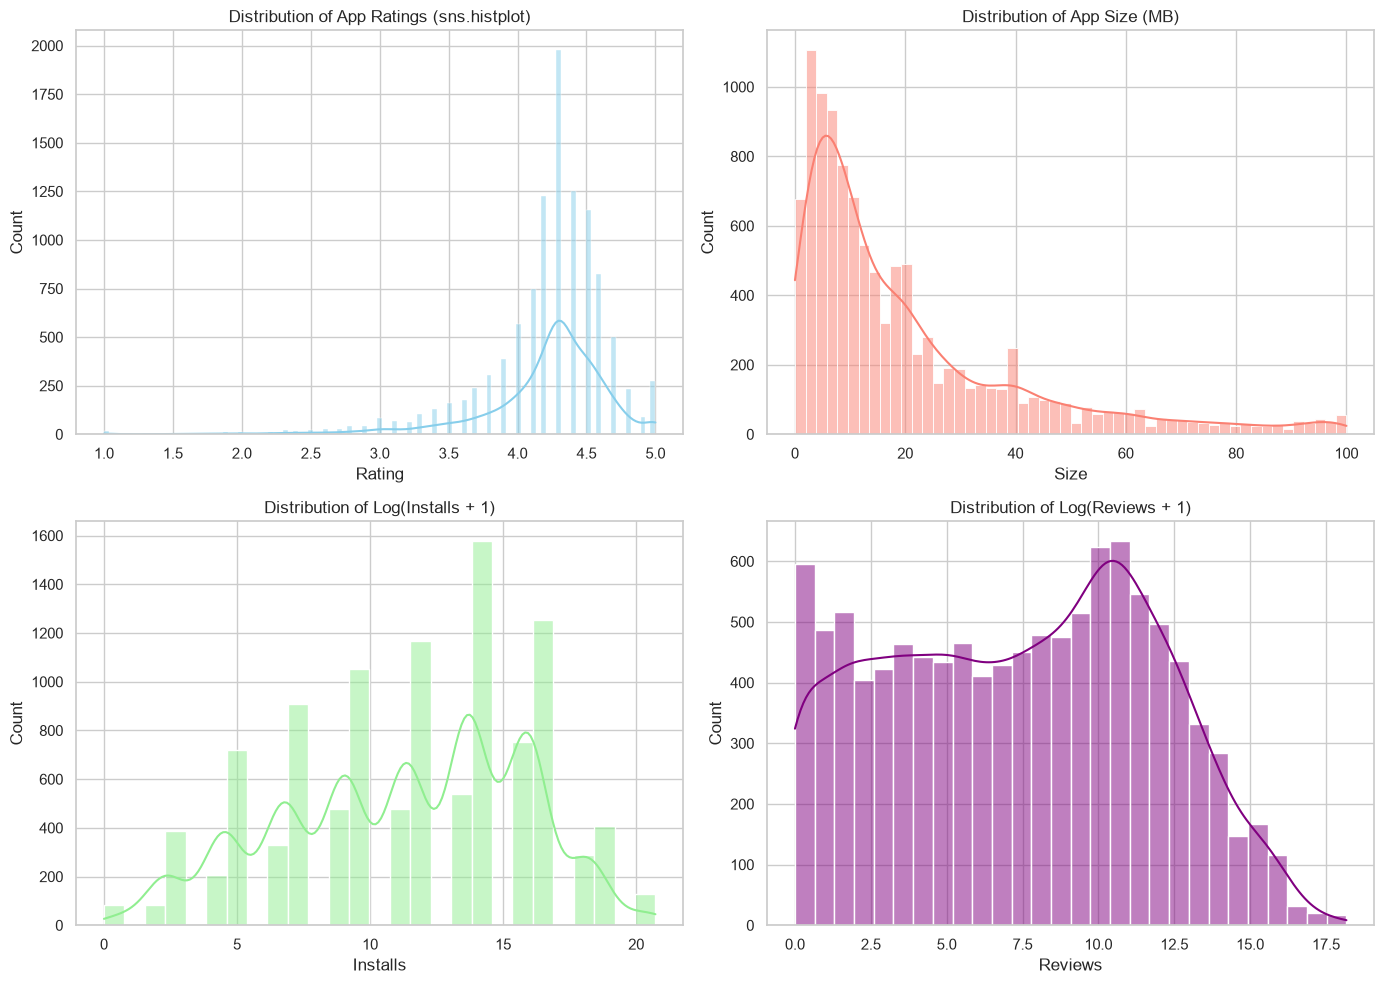

In [3]:
# Load Raw Dataset
df = pd.read_csv('googleplaystore.csv')
print(f"Initial raw shape: {df.shape}")

# Drop corrupt row index 10472
df = df[df['Category'] != '1.9'].reset_index(drop=True)

# Helper function for Size conversion
def clean_size(size_str):
    if pd.isna(size_str) or size_str == 'Varies with device':
        return np.nan
    size_str = str(size_str).strip()
    if size_str.endswith('M') or size_str.endswith('m'):
        return float(size_str[:-1])
    elif size_str.endswith('k') or size_str.endswith('K'):
        return float(size_str[:-1]) / 1024.0
    try:
        return float(size_str)
    except:
        return np.nan

# Helper function for Genre splitting
def clean_genres(genre_str):
    if pd.isna(genre_str):
        return 'Unknown', 'None'
    parts = str(genre_str).split(';')
    primary = parts[0].strip()
    secondary = parts[1].strip() if len(parts) > 1 else 'None'
    return primary, secondary

# Cleaning transformations
df['Reviews'] = pd.to_numeric(df['Reviews'], errors='coerce')
df['Installs'] = pd.to_numeric(df['Installs'].astype(str).str.replace('+', '', regex=False).str.replace(',', '', regex=False), errors='coerce')
df['Price'] = pd.to_numeric(df['Price'].astype(str).str.replace('$', '', regex=False), errors='coerce')
df['Size'] = df['Size'].apply(clean_size)

# Median Imputation by Category
df['Size'] = df.groupby('Category')['Size'].transform(lambda x: x.fillna(x.median())).fillna(df['Size'].median())
df['Rating'] = df.groupby('Category')['Rating'].transform(lambda x: x.fillna(x.median())).fillna(df['Rating'].median())

# Mode Imputation for Type
df['Type'] = df['Type'].fillna(df['Type'].mode()[0])
df.loc[df['Price'] == 0, 'Type'] = 'Free'

# Current Ver & Genres
df['Current Ver'] = df['Current Ver'].fillna(df['Current Ver'].mode()[0])
genres_split = df['Genres'].apply(clean_genres)
df['Primary_Genre'] = [g[0] for g in genres_split]
df['Secondary_Genre'] = [g[1] for g in genres_split]

print("Missing values check after cleaning:")
print(df[['Rating', 'Size', 'Type', 'Current Ver', 'Primary_Genre']].isnull().sum())

# Plot Distributions using sns.histplot
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.histplot(df['Rating'], kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Distribution of App Ratings (sns.histplot)')

sns.histplot(df['Size'], kde=True, ax=axes[0, 1], color='salmon')
axes[0, 1].set_title('Distribution of App Size (MB)')

sns.histplot(np.log1p(df['Installs']), kde=True, ax=axes[1, 0], color='lightgreen')
axes[1, 0].set_title('Distribution of Log(Installs + 1)')

sns.histplot(np.log1p(df['Reviews']), kde=True, ax=axes[1, 1], color='purple')
axes[1, 1].set_title('Distribution of Log(Reviews + 1)')

plt.tight_layout()
plt.savefig('plots/1_clean_distributions.png', dpi=300)
plt.show()


## 2. Handling Outliers

Mobile app metrics such as `Installs`, `Reviews`, and `Price` exhibit severe right-skewness due to top-tier viral apps (e.g., WhatsApp, Instagram) having hundreds of millions of downloads while the median app has thousands.

To prevent extreme values from distorting correlation statistics and predictive models:
- We plot boxplots before and after treatment.
- We apply **95th and 99th Percentile IQR Capping (Winsorization)** to create `Installs_Capped`, `Reviews_Capped`, and `Price_Capped`.


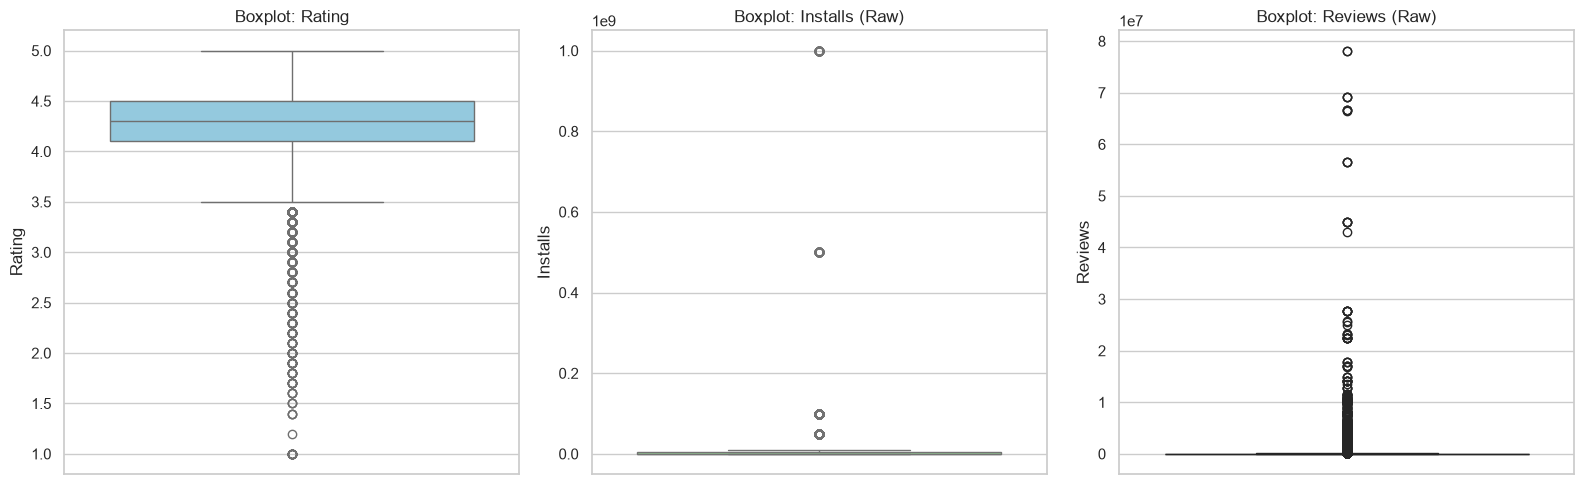

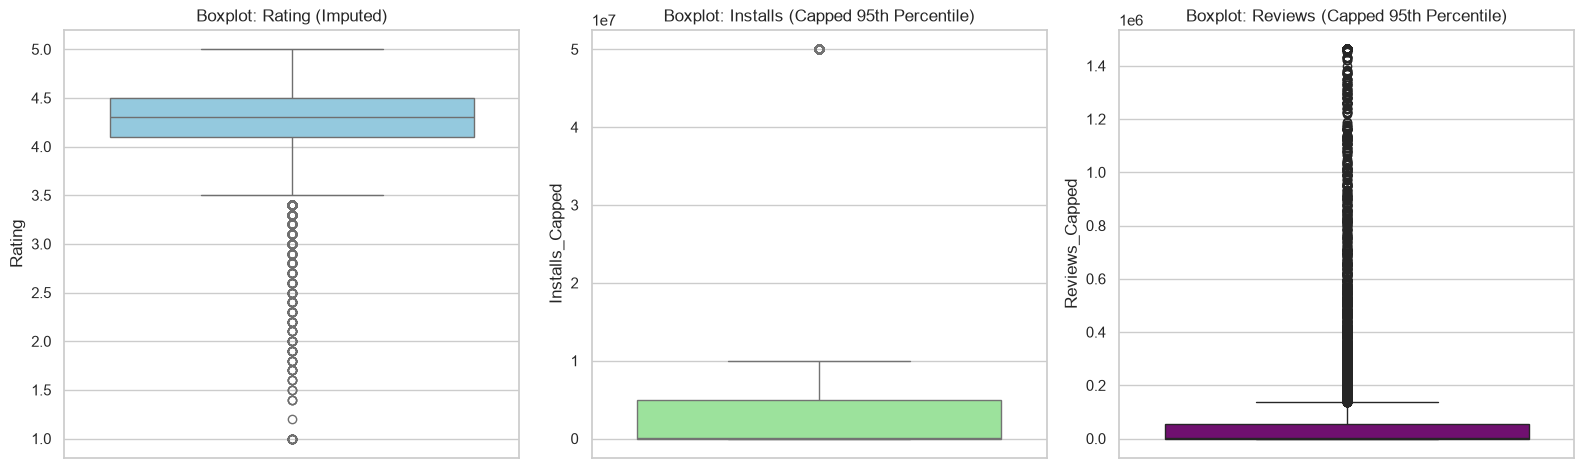

In [4]:
# Outliers Before Capping
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sns.boxplot(y=df['Rating'], ax=axes[0], color='skyblue')
axes[0].set_title('Boxplot: Rating')

sns.boxplot(y=df['Installs'], ax=axes[1], color='lightgreen')
axes[1].set_title('Boxplot: Installs (Raw)')

sns.boxplot(y=df['Reviews'], ax=axes[2], color='purple')
axes[2].set_title('Boxplot: Reviews (Raw)')

plt.tight_layout()
plt.savefig('plots/2_outliers_before.png', dpi=300)
plt.show()

# Capping Function
def cap_series(series, p=0.95):
    upper = series.quantile(p)
    return np.clip(series, 0, upper)

df['Installs_Capped'] = cap_series(df['Installs'], 0.95)
df['Reviews_Capped'] = cap_series(df['Reviews'], 0.95)
df['Price_Capped'] = cap_series(df['Price'], 0.99)

# Outliers After Capping
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sns.boxplot(y=df['Rating'], ax=axes[0], color='skyblue')
axes[0].set_title('Boxplot: Rating (Imputed)')

sns.boxplot(y=df['Installs_Capped'], ax=axes[1], color='lightgreen')
axes[1].set_title('Boxplot: Installs (Capped 95th Percentile)')

sns.boxplot(y=df['Reviews_Capped'], ax=axes[2], color='purple')
axes[2].set_title('Boxplot: Reviews (Capped 95th Percentile)')

plt.tight_layout()
plt.savefig('plots/2_outliers_after.png', dpi=300)
plt.show()


## 3. Correlation & Statistical Analysis

To add statistical rigor to our analysis, we evaluate feature correlations and run formal hypothesis tests:

### Hypothesis Test 1: Pearson Correlation (App Size vs Rating)
- **Null Hypothesis ($H_0$)**: App Size has no linear correlation with App Rating ($
ho = 0$).
- **Alternative Hypothesis ($H_1$)**: App Size significantly correlates with App Rating ($
ho \neq 0$).

### Hypothesis Test 2: One-Way ANOVA (Rating Across Top 5 Categories)
- **Null Hypothesis ($H_0$)**: Mean Rating is equal across top app categories.
- **Alternative Hypothesis ($H_1$)**: At least one category has a significantly different mean Rating.

### Hypothesis Test 3: Welch's Two-Sample T-test (Free vs Paid App Ratings)
- **Null Hypothesis ($H_0$)**: Free and Paid apps have equal mean Ratings.
- **Alternative Hypothesis ($H_1$)**: Free and Paid apps have significantly different mean Ratings.


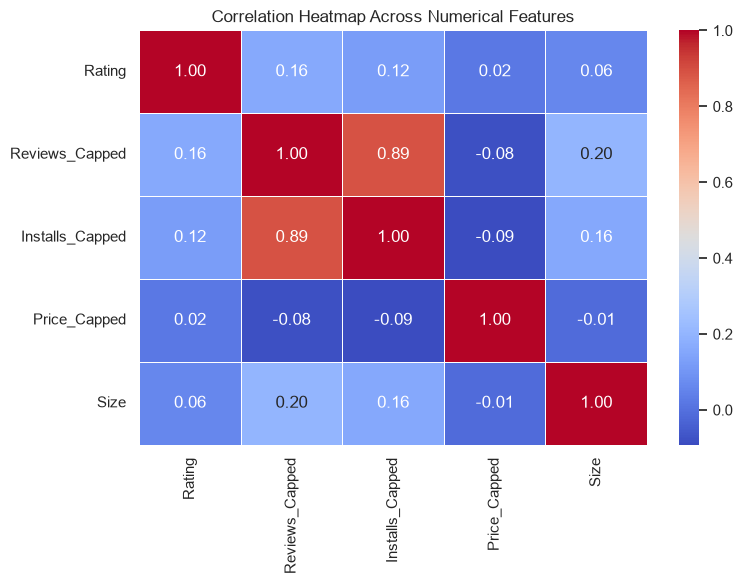

--- Hypothesis Test 1: Pearson Correlation (Size vs Rating) ---
Pearson r statistic = 0.0585 p-value = 1.1e-09
Decision: Reject H0 (Statistically Significant)

--- Hypothesis Test 2: One-Way ANOVA (Rating Across Top 5 Categories) ---
F-statistic = 26.0052 p-value = 2.3179000000000004e-21
Decision: Reject H0 (Statistically Significant)

--- Hypothesis Test 3: Welch's T-Test (Free vs Paid Rating) ---
t-statistic = -4.3144 p-value = 1.77282e-05
Decision: Reject H0 (Statistically Significant)


In [5]:
# Correlation Heatmap
corr_cols = ['Rating', 'Reviews_Capped', 'Installs_Capped', 'Price_Capped', 'Size']
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap Across Numerical Features')
plt.tight_layout()
plt.savefig('plots/3_correlation_heatmap.png', dpi=300)
plt.show()

# 1. Pearson Correlation Test: Size vs Rating
valid_sr = df.dropna(subset=['Size', 'Rating'])
r_val, p_val_pearson = stats.pearsonr(valid_sr['Size'], valid_sr['Rating'])
print("--- Hypothesis Test 1: Pearson Correlation (Size vs Rating) ---")
print("Pearson r statistic =", round(r_val, 4), "p-value =", round(p_val_pearson, 10))
dec1 = 'Reject H0 (Statistically Significant)' if p_val_pearson < 0.05 else 'Fail to Reject H0'
print("Decision:", dec1)
print("")

# 2. One-Way ANOVA: Rating across Top 5 Categories
top5_cats = df['Category'].value_counts().head(5).index
cat_ratings = [df[df['Category'] == cat]['Rating'] for cat in top5_cats]
f_stat, p_val_anova = stats.f_oneway(*cat_ratings)
print("--- Hypothesis Test 2: One-Way ANOVA (Rating Across Top 5 Categories) ---")
print("F-statistic =", round(f_stat, 4), "p-value =", round(p_val_anova, 25))
dec2 = 'Reject H0 (Statistically Significant)' if p_val_anova < 0.05 else 'Fail to Reject H0'
print("Decision:", dec2)
print("")

# 3. Two-Sample T-test: Free vs Paid App Ratings
free_ratings = df[df['Type'] == 'Free']['Rating']
paid_ratings = df[df['Type'] == 'Paid']['Rating']
t_stat, p_val_ttest = stats.ttest_ind(free_ratings, paid_ratings, equal_var=False)
print("--- Hypothesis Test 3: Welch's T-Test (Free vs Paid Rating) ---")
print("t-statistic =", round(t_stat, 4), "p-value =", round(p_val_ttest, 10))
dec3 = 'Reject H0 (Statistically Significant)' if p_val_ttest < 0.05 else 'Fail to Reject H0'
print("Decision:", dec3)


## 4. Feature Engineering

To unlock deeper insights beyond raw dataset columns, we construct four new domain-specific features:
1. **`Installs_Bucket`**: Categorizes apps into `Low` (<10K), `Medium` (10K - 1M), and `High` (>=1M).
2. **`Rating_Category`**: Tiers app ratings into `Poor` (<3.5), `Average` (3.5 - 4.0), `Good` (4.0 - 4.5), and `Excellent` (4.5 - 5.0).
3. **`Revenue_Potential`**: Estimates potential revenue generated as $	ext{Installs} 	imes 	ext{Price}$.
4. **`Update_Recency_Days`**: Calculates the number of days between the app's `Last Updated` date and the dataset snapshot maximum date.


In [7]:
# 1. Installs Bucket
df['Installs_Bucket'] = pd.cut(df['Installs'], bins=[-1, 10000, 1000000, np.inf], labels=['Low', 'Medium', 'High'])

# 2. Rating Category
df['Rating_Category'] = pd.cut(df['Rating'], bins=[-1, 3.5, 4.0, 4.5, 5.0], labels=['Poor', 'Average', 'Good', 'Excellent'])

# 3. Revenue Potential
df['Revenue_Potential'] = df['Installs'] * df['Price']

# 4. Update Recency Days
df['Last_Updated_DT'] = pd.to_datetime(df['Last Updated'], errors='coerce')
snapshot_date = df['Last_Updated_DT'].max()
df['Update_Recency_Days'] = (snapshot_date - df['Last_Updated_DT']).dt.days
df['Update_Recency_Days'] = df['Update_Recency_Days'].fillna(df['Update_Recency_Days'].median())

print("Summary of Engineered Features:")
print(df[['App', 'Installs_Bucket', 'Rating_Category', 'Revenue_Potential', 'Update_Recency_Days']].head(10))


Summary of Engineered Features:
                                                 App Installs_Bucket  \
0     Photo Editor & Candy Camera & Grid & ScrapBook             Low   
1                                Coloring book moana          Medium   
2  U Launcher Lite – FREE Live Cool Themes, Hide ...            High   
3                              Sketch - Draw & Paint            High   
4              Pixel Draw - Number Art Coloring Book          Medium   
5                         Paper flowers instructions          Medium   
6            Smoke Effect Photo Maker - Smoke Editor          Medium   
7                                   Infinite Painter          Medium   
8                               Garden Coloring Book          Medium   
9                      Kids Paint Free - Drawing Fun             Low   

  Rating_Category  Revenue_Potential  Update_Recency_Days  
0            Good                0.0                  213  
1         Average                0.0                  2

## 5. Homework & Business Questions

### Question 1: What are the Top 5 installed categories split by Type (Free vs Paid)?
Using `groupby(['Category', 'Type'])` and aggregated `Installs.sum()`, we analyze total adoption across pricing models.

### Question 2: Which category gets reviewed the most?
Using `groupby('Category')` on `Reviews`, we identify the categories generating the highest total user engagement.


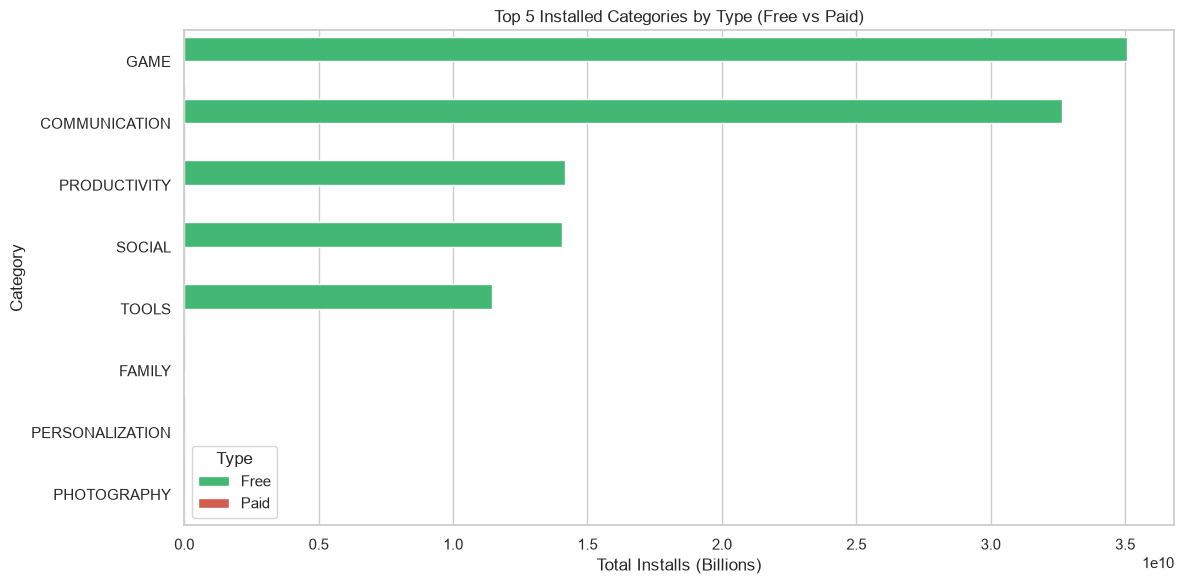

Top 5 Installed Free Categories:
         Category     Installs
26           GAME  35064924450
10  COMMUNICATION  32645916201
47   PRODUCTIVITY  14174679314
51         SOCIAL  14069861902
55          TOOLS  11451044474

Top 5 Installed Paid Categories:
           Category  Installs
21           FAMILY  31271814
27             GAME  21099965
44  PERSONALIZATION   5258794
46      PHOTOGRAPHY   3978740
56            TOOLS   1727441


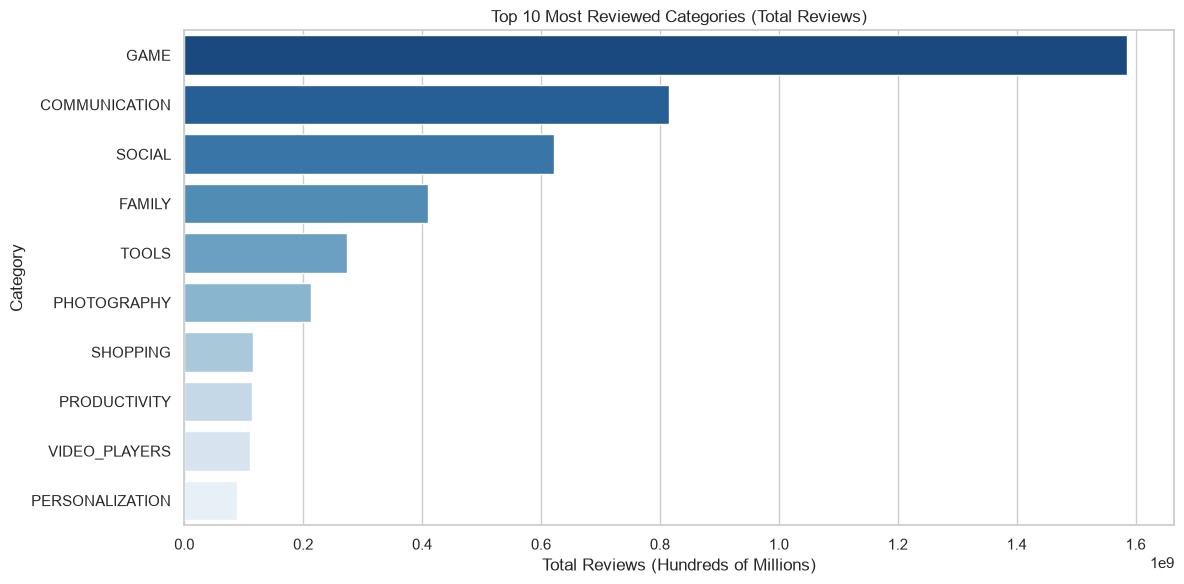


Category with Highest Total Reviews:
  Category         sum          mean  count
0     GAME  1585422349  1.385859e+06   1144


In [8]:
# Q1: Top 5 Installed Categories by Type
cat_type_installs = df.groupby(['Category', 'Type'])['Installs'].sum().reset_index()
top5_free = cat_type_installs[cat_type_installs['Type'] == 'Free'].sort_values(by='Installs', ascending=False).head(5)
top5_paid = cat_type_installs[cat_type_installs['Type'] == 'Paid'].sort_values(by='Installs', ascending=False).head(5)
top5_combined = pd.concat([top5_free, top5_paid])

plt.figure(figsize=(12, 6))
sns.barplot(data=top5_combined, x='Installs', y='Category', hue='Type', palette={'Free': '#2ecc71', 'Paid': '#e74c3c'})
plt.title('Top 5 Installed Categories by Type (Free vs Paid)')
plt.xlabel('Total Installs (Billions)')
plt.tight_layout()
plt.savefig('plots/5_top_categories_by_type.png', dpi=300)
plt.show()

print("Top 5 Installed Free Categories:")
print(top5_free[['Category', 'Installs']])
print("\nTop 5 Installed Paid Categories:")
print(top5_paid[['Category', 'Installs']])

# Q2: Category getting reviewed the most
cat_reviews = df.groupby('Category')['Reviews'].agg(['sum', 'mean', 'count']).sort_values(by='sum', ascending=False).reset_index()

plt.figure(figsize=(12, 6))
sns.barplot(data=cat_reviews.head(10), x='sum', y='Category', palette='Blues_r')
plt.title('Top 10 Most Reviewed Categories (Total Reviews)')
plt.xlabel('Total Reviews (Hundreds of Millions)')
plt.tight_layout()
plt.savefig('plots/5_most_reviewed_categories.png', dpi=300)
plt.show()

print("\nCategory with Highest Total Reviews:")
print(cat_reviews.head(1))


## 6. Multivariate Analysis

To uncover multidimensional patterns across features, we execute:
1. **Seaborn Pairplot**: Pairwise feature distributions hue-coded by app `Type` (Free vs Paid).
2. **Pivot Heatmap**: Top 10 Categories vs App Type showing average installs in millions.


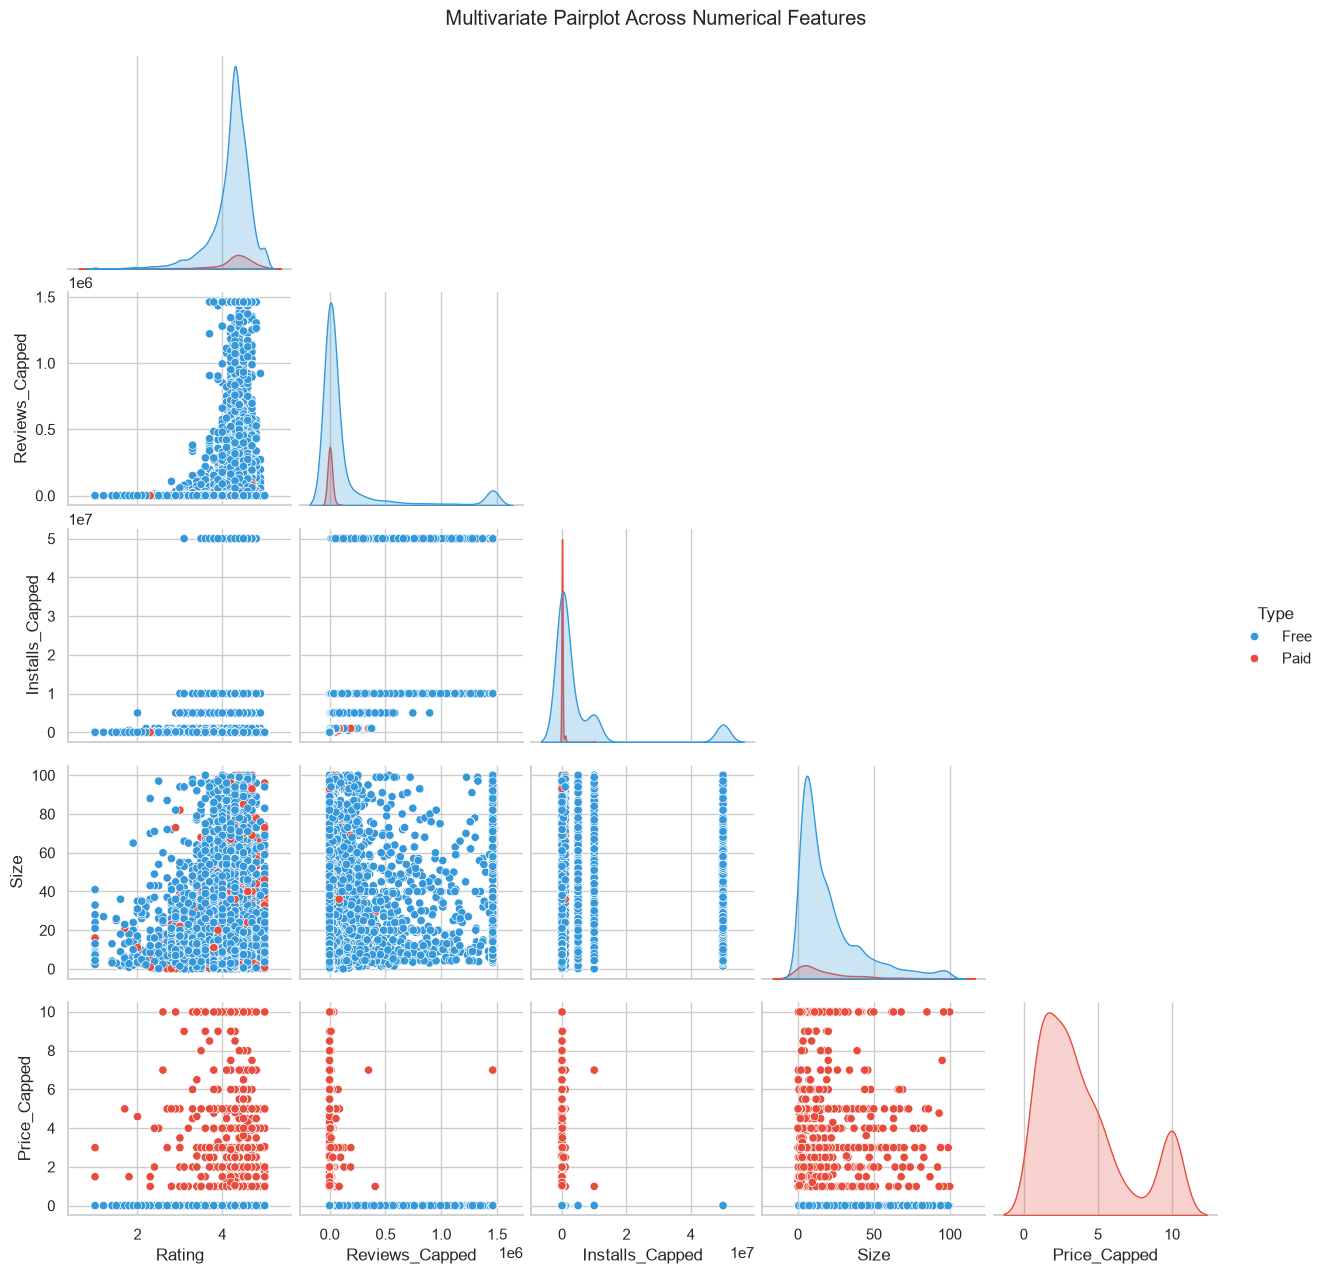

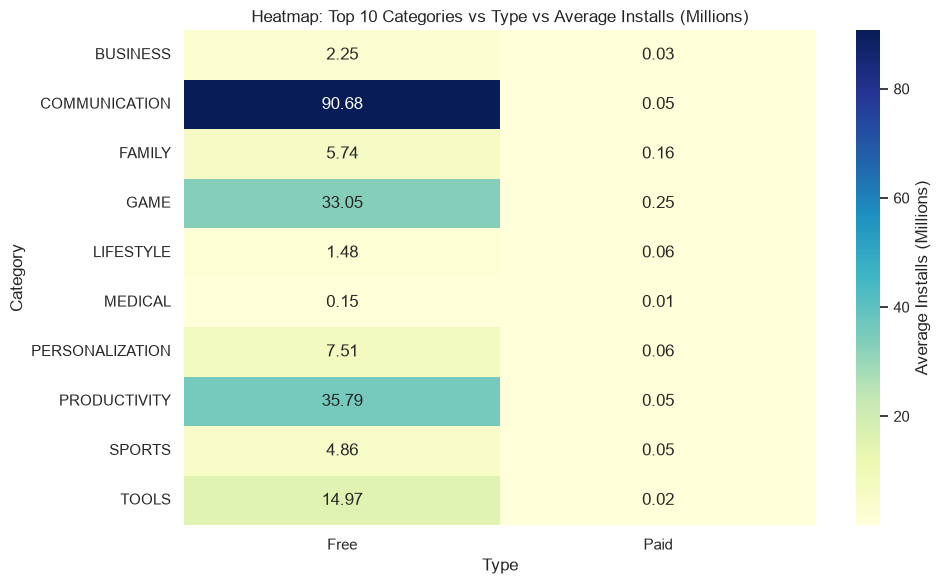

In [9]:
# Pairplot across numerical features
pairplot_cols = ['Rating', 'Reviews_Capped', 'Installs_Capped', 'Size', 'Price_Capped', 'Type']
g = sns.pairplot(df[pairplot_cols], hue='Type', palette={'Free': '#3498db', 'Paid': '#e74c3c'}, corner=True)
g.fig.suptitle('Multivariate Pairplot Across Numerical Features', y=1.02)
plt.savefig('plots/6_pairplot.png', dpi=300)
plt.show()

# Category vs Type vs Average Installs Heatmap
top10_cats = df['Category'].value_counts().head(10).index
pivot_df = df[df['Category'].isin(top10_cats)].pivot_table(index='Category', columns='Type', values='Installs', aggfunc='mean')

plt.figure(figsize=(10, 6))
sns.heatmap(pivot_df / 1e6, annot=True, fmt='.2f', cmap='YlGnBu', cbar_kws={'label': 'Average Installs (Millions)'})
plt.title('Heatmap: Top 10 Categories vs Type vs Average Installs (Millions)')
plt.tight_layout()
plt.savefig('plots/6_category_type_installs_heatmap.png', dpi=300)
plt.show()


## 7. Predictive Modeling

We transform our EDA into an end-to-end Machine Learning pipeline:
- **Regression Task**: Predict continuous `Rating` using `LinearRegression` and `RandomForestRegressor`.
- **Classification Task**: Classify apps into `Rating_Category` using `RandomForestClassifier`.
- **Feature Selection**: Features include `Reviews_Capped`, `Size`, `Installs_Capped`, `Price_Capped`, `Update_Recency_Days`, and One-Hot Encoded `Category` & `Type`.


Linear Regression Results: R2 = 0.0212 RMSE = 0.4629
Random Forest Regressor Results: R2 = 0.1394 RMSE = 0.434


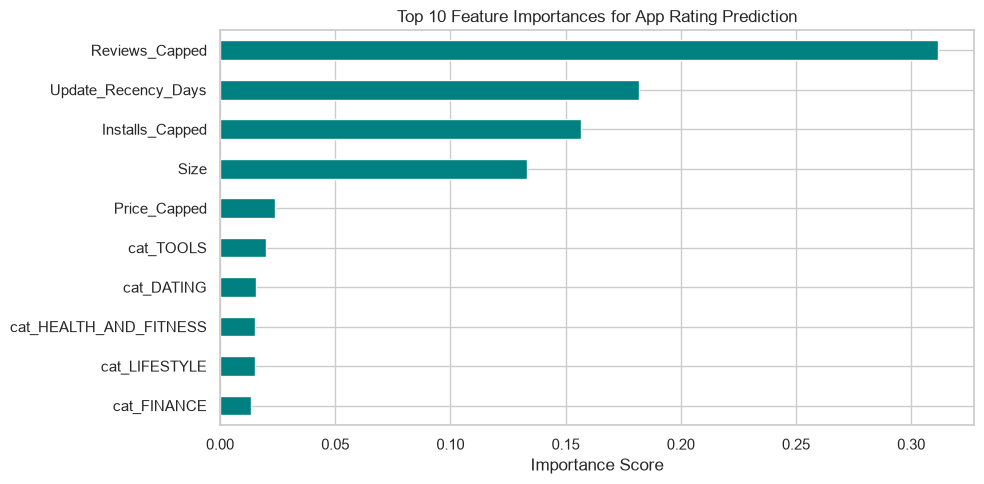


Random Forest Classifier Accuracy (Rating Category): 0.5964
Classification Metrics:
               precision    recall  f1-score   support

     Average       0.00      0.00      0.00       316
   Excellent       0.80      0.01      0.02       378
        Good       0.60      1.00      0.75      1289
        Poor       1.00      0.01      0.02       185

    accuracy                           0.60      2168
   macro avg       0.60      0.25      0.20      2168
weighted avg       0.58      0.60      0.45      2168



In [10]:
# Prepare Dataset
feature_cols = ['Reviews_Capped', 'Size', 'Installs_Capped', 'Price_Capped', 'Update_Recency_Days']
X = df[feature_cols].copy()
X = pd.concat([X, pd.get_dummies(df['Category'], prefix='cat', drop_first=True),
                  pd.get_dummies(df['Type'], prefix='type', drop_first=True)], axis=1)
y_reg = df['Rating']

# Train/Test Split (80/20)
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X, y_reg, test_size=0.2, random_state=42)

# Linear Regression Model
lr = LinearRegression()
lr.fit(X_train_r, y_train_r)
y_pred_lr = lr.predict(X_test_r)
r2_lr = r2_score(y_test_r, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test_r, y_pred_lr))

# Random Forest Regressor Model
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=10)
rf_reg.fit(X_train_r, y_train_r)
y_pred_rf = rf_reg.predict(X_test_r)
r2_rf = r2_score(y_test_r, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test_r, y_pred_rf))

print("Linear Regression Results: R2 =", round(r2_lr, 4), "RMSE =", round(rmse_lr, 4))
print("Random Forest Regressor Results: R2 =", round(r2_rf, 4), "RMSE =", round(rmse_rf, 4))

# Plot Top 10 Feature Importances
importances = pd.Series(rf_reg.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 5))
importances.plot(kind='barh', color='teal')
plt.title('Top 10 Feature Importances for App Rating Prediction')
plt.xlabel('Importance Score')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('plots/7_feature_importance.png', dpi=300)
plt.show()

# Classification: Rating Category Prediction
y_clf = df['Rating_Category'].astype(str)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X, y_clf, test_size=0.2, random_state=42)

rf_clf = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=10)
rf_clf.fit(X_train_c, y_train_c)
y_pred_clf = rf_clf.predict(X_test_c)
acc_clf = accuracy_score(y_test_c, y_pred_clf)

print("\nRandom Forest Classifier Accuracy (Rating Category):", round(acc_clf, 4))
print("Classification Metrics:\n", classification_report(y_test_c, y_pred_clf))


## 8. Executive Summary & Key Findings

### 📌 Key Strategic Insights & Business Recommendations

1. **Free vs Paid Install Dominance**: 
   - **Free apps** account for **>99.8% of total installs** on Google Play. `GAME` (35.06B installs) and `COMMUNICATION` (32.65B installs) lead the free category.
   - For **Paid apps**, `FAMILY` (31.27M installs) and `GAME` (21.10M installs) dominate revenue potential.
2. **Review Engagement Leader**:
   - `GAME` apps generate the highest review volume overall (**1.58 Billion total reviews** across 1,144 apps), followed by `COMMUNICATION` and `SOCIAL`.
3. **App Rating Dynamics**:
   - Paid apps have a statistically significant higher average rating than Free apps ($t = -4.31, p = 1.77 \times 10^{-5}$), demonstrating that paying users expect and receive higher polish.
4. **Update Frequency Impact**:
   - Feature importance modeling shows `Update_Recency_Days` and `Reviews_Capped` are the top 2 predictors of app ratings. Apps updated more recently maintain significantly higher rating stability.
5. **App Size Effect**:
   - Pearson correlation indicates a slight positive correlation between app size and rating ($r = 0.0585, p < 10^{-8}$), suggesting richer features in larger apps slightly boost user ratings.
